<font face="Times New Roman" size=5>
<div dir=rtl align="center">
<font face="Times New Roman" size=5>

</font>
<br>
<img src="https://logoyar.com/content/wp-content/uploads/2021/04/sharif-university-logo.png" alt="University Logo" width="150" height="150">
<br>
<font face="Times New Roman" size=4 align=center>
Sharif University of Technology - Department of Electrical Engineering
</font>
<br>
<font color="#008080" size=6>
Deep Generative Models
</font>

<hr/>
<font color="#800080" size=5>
Assignment 3
<br>
</font>
<font size=5>
Instructor: Dr. S. Amini
<br>
</font>
<font size=4>
Fall 2025
<br>
</font>
<!-- <font face="Times New Roman" size=4>
Deadline:
</font> -->
<hr>
</div></font>

*name* = "Seyed Ali Vakilzadeh"

studentId = "401102789"

It is recommended to open this notebook in Google Colab from [here](https://colab.research.google.com/drive/1oRa8tpMWx52pxfydpwQloKIYseZOA-z2?usp=sharing) and create a copy. You can comment your questions on the notebook as well.

In this exercise we want to gain hands-on experience with Normalizing Flow Models.
1. We want to implement simple flow models from scratch. (GPU not required)
2. We will use a flow model to perform image in-painting. (GPU recommended)

# Section 1: Flow From Scratch

In [11]:
# @title imports
import torch
import torch.nn as nn
import torch.optim as optim
import torch.distributions as D
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from tqdm import tqdm
import numpy as np

import time

In [12]:
# @title settings
# @title settings

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

## Transforms

One of the challenges in creating flow models is creating **invertible** transformations with computable **Jacobian determinant**. We will create such transformations now.

In [3]:
# @title Base Transform classes / helpers

class InverseNotAvailable(Exception):
    pass

class Transform(nn.Module):
    """Base class for invertible transform objects.

    Every transform.forward returns (y, log_det_J) where log_det_J is a tensor
    shaped (batch,) or a scalar (will be broadcasted).
    inverse(...) should return the inverse mapping (no log-det returned).
    """
    def forward(self, inputs, context=None):
        raise NotImplementedError()

    def inverse(self, inputs, context=None):
        raise InverseNotAvailable()

First lets create a permutation transform

In [18]:
class PermutationTransform(Transform):
    def __init__(self, num_features, permutation=None):
        super().__init__()
        if permutation is None:
            permutation = torch.randperm(num_features)
        else:
            permutation = torch.as_tensor(permutation, dtype=torch.long)

        self.register_buffer("permutation", permutation)
        self.register_buffer("inverse_permutation", torch.argsort(permutation))
        self.num_features = num_features

    def forward(self, inputs, context=None):
        x_perm = inputs[:, self.permutation]
        log_det = inputs.new_zeros(inputs.size(0))
        return x_perm, log_det

    def inverse(self, inputs, context=None):
        x = inputs[:, self.inverse_permutation]
        return x


Now create an ActNorm Transform. Learnable per-channel scale & bias with data-dependent init

In [5]:
class ActNorm(Transform):
    def __init__(self, num_features):
        super().__init__()
        self.num_features = num_features
        self.bias = nn.Parameter(torch.zeros(1, num_features))
        self.log_scale = nn.Parameter(torch.zeros(1, num_features))
        self.initialized = False

    def forward(self, x, context=None):
        if (not self.initialized) and self.training:
            with torch.no_grad():
                mean = x.mean(dim=0, keepdim=True)
                std = x.std(dim=0, keepdim=True)
                self.bias.data = -mean
                self.log_scale.data = -torch.log(std + 1e-6)
            self.initialized = True

        y = (x + self.bias) * torch.exp(self.log_scale)
        log_det = torch.sum(self.log_scale, dim=1).expand(x.shape[0])
        return y, log_det

    def inverse(self, y, context=None):
        x = y * torch.exp(-self.log_scale) - self.bias
        return x


Create an invertible linear (dense) layer with orthogonal / LU parametrization. Inspired by the 1x1 convolution used in Glow.

In [6]:
class InvertibleLinear(Transform):
    def __init__(self, num_features, use_lu=False):
        super().__init__()
        self.num_features = num_features
        self.use_lu = use_lu

        if not use_lu:
            w = torch.randn(num_features, num_features)
            q, r = torch.linalg.qr(w)
            self.weight = nn.Parameter(q)
            return

        w = torch.randn(num_features, num_features)
        q, r = torch.linalg.qr(w)

        P, L, U = torch.linalg.lu(q)
        self.register_buffer("P", P)

        L_mask = torch.tril(torch.ones(num_features, num_features, device=L.device, dtype=L.dtype), diagonal=-1)
        self.register_buffer("L_mask", L_mask)

        U_mask = torch.triu(torch.ones(num_features, num_features, device=U.device, dtype=U.dtype), diagonal=0)
        self.register_buffer("U_mask", U_mask)

        self.L_params = nn.Parameter(L * L_mask)
        self.U_params = nn.Parameter(U * U_mask)

        diag_U = torch.diag(U)
        sign_diag_U = torch.sign(diag_U)
        sign_diag_U = torch.where(sign_diag_U == 0, torch.ones_like(sign_diag_U), sign_diag_U)
        self.register_buffer("sign_diag_U", sign_diag_U)

        self.log_diag_U = nn.Parameter(torch.log(torch.abs(diag_U) + 1e-6))

    def _assemble_weight(self):
        if not self.use_lu:
            return self.weight

        n = self.num_features
        I = torch.eye(n, device=self.L_params.device, dtype=self.L_params.dtype)

        L = I + self.L_params * self.L_mask

        U = self.U_params * self.U_mask
        U = U - torch.diag(torch.diag(U))
        U = U + torch.diag(self.sign_diag_U * torch.exp(self.log_diag_U))

        W = self.P @ L @ U
        return W

    def forward(self, x, context=None):
        W = self._assemble_weight()
        y = x @ W.t()

        if self.use_lu:
            log_det = torch.sum(self.log_diag_U)
            log_det = log_det * torch.ones(x.size(0), device=x.device)
        else:
            sign, logabsdet = torch.slogdet(W)
            log_det = logabsdet * torch.ones(x.size(0), device=x.device)

        return y, log_det

    def inverse(self, y, context=None):
        W = self._assemble_weight()
        W_inv = torch.inverse(W)
        return y @ W_inv.t()


Now  lets create a simple Affine Coupling Transform. From RealNVP.

$$y_d = x_d * \exp(s(x_a)) + t(x_a)$$

In [7]:
class AffineCouplingTransform(Transform):
    def __init__(self, mask, hidden_dims=128, s_net_f=None, t_net_f=None):
        super().__init__()

        mask = torch.as_tensor(mask, dtype=torch.float32)
        if mask.dim() != 1:
            raise ValueError("Mask must be a 1-dim tensor.")
        if mask.numel() <= 0:
            raise ValueError("Mask can't be empty.")

        self.register_buffer("mask", mask)
        self.num_features = self.mask.numel()

        features_vector = torch.arange(self.num_features)
        self.identity_idx = features_vector[self.mask == 0]
        self.transform_idx = features_vector[self.mask == 1]

        in_dim = len(self.identity_idx)
        out_dim = len(self.transform_idx)

        if s_net_f is None:
            self.s = self._net(in_dim, out_dim, hidden_dims)
        else:
            self.s = s_net_f(in_dim, out_dim, hidden_dims)

        if t_net_f is None:
            self.t = self._net(in_dim, out_dim, hidden_dims)
        else:
            self.t = t_net_f(in_dim, out_dim, hidden_dims)

        for m in [self.s, self.t]:
            if isinstance(m, nn.Sequential) and isinstance(m[-1], nn.Linear):
                nn.init.zeros_(m[-1].weight)
                nn.init.zeros_(m[-1].bias)

    def _net(self, input_dim, output_dim, hidden_dims):
        net = nn.Sequential(
            nn.Linear(input_dim, hidden_dims),
            nn.ReLU(),
            nn.Linear(hidden_dims, hidden_dims),
            nn.ReLU(),
            nn.Linear(hidden_dims, output_dim),
        )
        return net

    def forward(self, x, context=None):
        if x.dim() != 2:
            raise ValueError("Expect 2D inputs")

        x_id = x[:, self.identity_idx]
        x_tr = x[:, self.transform_idx]

        s = self.s(x_id)
        s = 2.0 * torch.tanh(s)
        t = self.t(x_id)

        y_tr = x_tr * torch.exp(s) + t

        y = x.clone()
        y[:, self.identity_idx] = x_id
        y[:, self.transform_idx] = y_tr

        log_det = torch.sum(s, dim=1)
        return y, log_det

    def inverse(self, y, context=None):
        if y.dim() != 2:
            raise ValueError("Expect 2D inputs")

        y_id = y[:, self.identity_idx]
        y_tr = y[:, self.transform_idx]

        s = self.s(y_id)
        s = 2.0 * torch.tanh(s)
        t = self.t(y_id)

        x_tr = (y_tr - t) * torch.exp(-s)

        x = y.clone()
        x[:, self.identity_idx] = y_id
        x[:, self.transform_idx] = x_tr
        return x


## Model

In this step we implement a simple Normalizing Flow model (RealNVP-like).
The model consists of:
  - a sequence of invertible transforms
  - a base Gaussian distribution
The Flow class is generic: it can (mostly) work with any sequence of invertible transforms.

In [8]:
class Flow(nn.Module):
    def __init__(self, transforms, base_distribution=None):
        super(Flow, self).__init__()
        self.transforms = nn.ModuleList(transforms).to(device)
        self.num_features = self.transforms[0].num_features
        if base_distribution is None:
            self.base_distribution = D.MultivariateNormal(
                loc=torch.zeros(self.num_features, device=device),
                covariance_matrix=torch.eye(self.num_features, device=device)
            )
        else:
            self.base_distribution = base_distribution

    def forward(self, x):
        log_det_total = torch.zeros(x.size(0), device=x.device)
        z = x
        for t in self.transforms:
            z, log_det = t.forward(z)
            if torch.is_tensor(log_det) and log_det.dim() == 0:
                log_det = log_det.expand(z.size(0))
            log_det_total = log_det_total + log_det
        return z, log_det_total

    def inverse(self, z):
        x = z
        for t in reversed(self.transforms):
            x = t.inverse(x)
        return x

    def log_prob(self, x):
        z, log_det = self.forward(x)
        base_lp = self.base_distribution.log_prob(z)
        return base_lp + log_det

    def sample(self, num_samples):
        z = self.base_distribution.sample((num_samples,))
        x = self.inverse(z)
        return x

    def sample_and_log_prob(self, num_samples):
        z = self.base_distribution.sample((num_samples,))
        log_pz = self.base_distribution.log_prob(z)
        x = self.inverse(z)
        _, log_det = self.forward(x)
        log_px = log_pz + log_det
        return x, log_px


Now  we initialize the model and coupling layers. We then train the model on the simple Moons dataset and visualize its learning process through its latent space.

In [9]:
# Mask helper
def make_masks(num_features, alternating=True):
    if alternating:
        return [(i % 2) for i in range(num_features)]
    else:
        return [((i+1) % 2) for i in range(num_features)]

In [10]:
def build_realnvp_flow(num_features=2, n_couplings=6, hidden_dims=128):
    transforms = []

    transforms.append(ActNorm(num_features))

    for i in range(n_couplings):
        mask = make_masks(num_features, alternating=(i % 2 == 0))
        transforms.append(AffineCouplingTransform(mask=mask, hidden_dims=hidden_dims))
        transforms.append(InvertibleLinear(num_features=num_features, use_lu=(i % 2 == 0)))

    return Flow(transforms).to(device)


def build_permut_flow(num_features=2, n_couplings=6, hidden_dims=128):
    transforms = []

    transforms.append(ActNorm(num_features))

    for i in range(n_couplings):
        mask = make_masks(num_features, alternating=(i % 2 == 0))
        transforms.append(AffineCouplingTransform(mask=mask, hidden_dims=hidden_dims))
        transforms.append(PermutationTransform(num_features=num_features))

    return Flow(transforms).to(device)

In [15]:
def train_flow(flow,
              X,
              num_epochs=1000,
              batch_size=256,
              lr=1e-3,
              log_interval=50,
              verbose=True):
    flow = flow.to(device)
    opt = optim.Adam(flow.parameters(), lr=lr)
    dataset = torch.utils.data.TensorDataset(X)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    loss_history = []
    pbar = tqdm(range(num_epochs), disable=not verbose)

    for epoch in pbar:
        epoch_loss = 0.0
        num_seen = 0

        for (batch,) in loader:
            opt.zero_grad(set_to_none=True)

            nll = -flow.log_prob(batch)
            loss = nll.mean()

            loss.backward()
            opt.step()

            bs = batch.size(0)
            epoch_loss += loss.item() * bs
            num_seen += bs

        epoch_loss = epoch_loss / max(1, num_seen)
        loss_history.append(epoch_loss)

        if verbose and (epoch % log_interval == 0 or epoch == num_epochs - 1):
            pbar.set_description(f"Epoch {epoch} loss {loss_history[-1]:.4f}")

            if (epoch % (log_interval) == 0) and X.shape[1] == 2:
                with torch.no_grad():
                    xline = torch.linspace(-1.5, 2.5, 200, device=device)
                    yline = torch.linspace(-0.75, 1.25, 200, device=device)
                    xgrid, ygrid = torch.meshgrid(xline, yline, indexing='ij')

                    xy = torch.stack([xgrid.flatten(), ygrid.flatten()], dim=1)

                    log_prob_grid = flow.log_prob(xy)
                    zgrid = torch.exp(log_prob_grid).reshape(200, 200).cpu()

                plt.figure(figsize=(8, 6))
                plt.contourf(
                    xgrid.cpu().numpy(),
                    ygrid.cpu().numpy(),
                    zgrid.numpy(),
                    levels=50,
                    cmap='viridis'
                )
                plt.title(f"Epoch {epoch}")
                plt.xlabel('x1')
                plt.ylabel('x2')
                plt.colorbar(label='Density')
                plt.show()

    return flow, loss_history

## Training and Evaluation

In this step you will:
  - Train two types of flows on the make_moons dataset
  - Compare their training losses
  - Visualize density contours
  - Visualize generated samples


You are encouraged to add your own configurations and their names to `flow_names` and find better results.

You may **slightly** modify the visualization codes to match your code but this is discouraged.

In [19]:
# Hyperparameters
num_features = 2
hidden_dims = 128
batch_size = 256
learning_rate = 1e-3
num_epochs = 1000
n_couplings=6
num_samples_plot=1000
show_density=True

# Prepare data
X_np, _ = make_moons(n_samples=2000, noise=0.08, random_state=SEED)
X = torch.tensor(X_np, dtype=torch.float32).to(device)

results = {}
flow_names = ['RealNVP', 'PermutFlow']
for name in flow_names:
    print(f"\n========================================")
    print(f"\n=== Building & training flow: {name} ===")
    if name == 'RealNVP':
        flow = build_realnvp_flow(num_features=num_features, n_couplings=n_couplings, hidden_dims=hidden_dims)
    elif name == 'PermutFlow':
        flow = build_permut_flow(num_features=num_features, n_couplings=n_couplings, hidden_dims=hidden_dims)
    else:
        raise ValueError(f"Unknown flow name: {name}")

    start = time.time()
    trained_flow, losses = train_flow(flow, X,
                                      num_epochs=num_epochs,
                                      batch_size=batch_size,
                                      lr=learning_rate,
                                      log_interval=max(1, num_epochs//20),
                                      verbose=True)
    elapsed = time.time() - start
    print(f"Trained {name} in {elapsed:.1f}s; final loss {losses[-1]:.4f}")
    results[name] = {'flow': trained_flow, 'losses': losses}


Output hidden; open in https://colab.research.google.com to view.

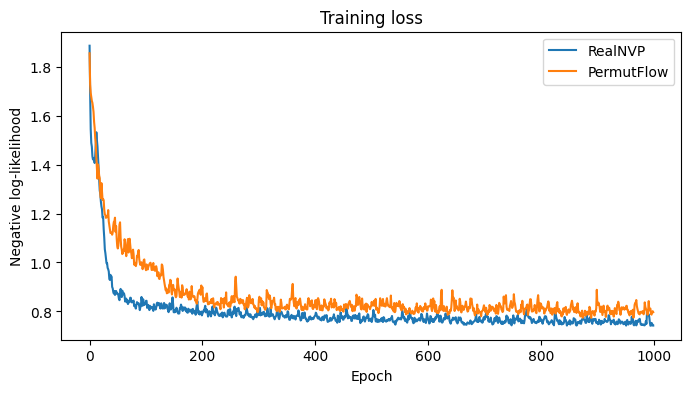

In [20]:
# Plotting training losses
plt.figure(figsize=(8,4))
for name, info in results.items():
    plt.plot(info['losses'], label=name)
plt.xlabel('Epoch')
plt.ylabel('Negative log-likelihood')
plt.legend()
plt.title('Training loss')
plt.show()


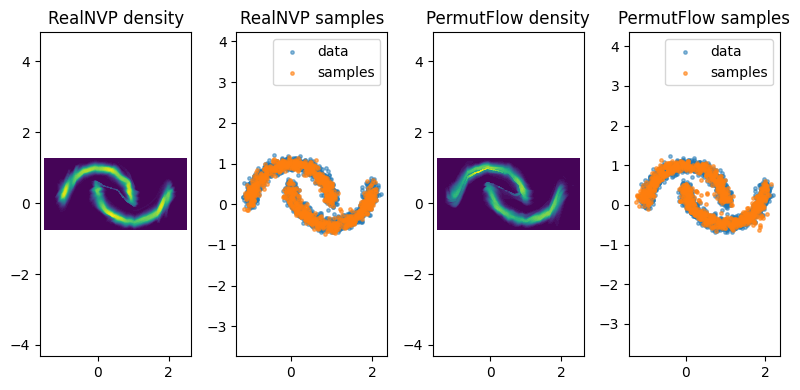

In [21]:
# Plot densities and samples for each model
xline = torch.linspace(-1.5, 2.5, 200, device=device)
yline = torch.linspace(-0.75, 1.25, 200, device=device)
xgrid, ygrid = torch.meshgrid(xline, yline, indexing='ij')
xy = torch.stack([xgrid.flatten(), ygrid.flatten()], dim=1).to(device)

n_variants = len(flow_names)
cols = min(3, n_variants)
rows = int(np.ceil(n_variants / cols))

plt.figure(figsize=(4*cols, 4*rows))
i = 1
for name in flow_names:
    info = results[name]
    f = info['flow']
    with torch.no_grad():
        logp = f.log_prob(xy)
        density = torch.exp(logp).reshape(xgrid.shape).cpu().numpy()
        samples = f.sample(num_samples_plot).cpu().numpy()

    # Density subplot
    plt.subplot(rows, cols*2, 2*(i-1)+1)
    if show_density:
        plt.contourf(xgrid.cpu().numpy(), ygrid.cpu().numpy(), density, levels=50)
        plt.title(f"{name} density")
        plt.axis('equal')
    else:
        plt.title(f"{name} density (hidden)")
        plt.axis('off')

    # Samples subplot
    plt.subplot(rows, cols*2, 2*(i-1)+2)
    plt.scatter(X.cpu().numpy()[:,0], X.cpu().numpy()[:,1], s=6, label='data', alpha=0.5)
    plt.scatter(samples[:,0], samples[:,1], s=6, label='samples', alpha=0.6)
    plt.title(f"{name} samples")
    plt.axis('equal')
    plt.legend()
    i += 1

plt.tight_layout()
plt.show()

# Section 2: Image Inpainting

In [2]:
!pip install normflows --quiet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.3/65.3 kB 4.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [3]:
# Import required packages
import os
import math
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt

import torch
import torch.optim as optim
import torchvision as tv

import normflows as nf

In [4]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
# Make CUDA deterministic *if* you want strict reproducibility (may be slower)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

Using device: cuda


Now that we imported the necessary packages, we create a flow model. Glow consists of `nf.flows.GlowBlocks`, that are arranged in a `nf.MultiscaleFlow`, following the multi-scale architecture.


In [5]:
# Define the directory to save checkpoints
checkpoint_dir = 'checkpoints'
os.makedirs(checkpoint_dir, exist_ok=True)

In [6]:
# Set up model

# Define flows
L = 2
K = 16
torch.manual_seed(SEED)

input_shape = (1, 28, 28)
n_dims = np.prod(input_shape)
channels = 1
hidden_channels = 128
split_mode = 'channel'
scale = True
num_classes = 10

# Set up flows, distributions and merge operations
q0 = []
merges = []
flows = []
for i in range(L):
    flows_ = []
    for j in range(K):
        flows_ += [nf.flows.GlowBlock(channels * 2 ** (L + 1 - i), hidden_channels,
                                     split_mode=split_mode, scale=scale)]
    flows_ += [nf.flows.Squeeze()]
    flows += [flows_]
    if i > 0:
        merges += [nf.flows.Merge()]
        latent_shape = (input_shape[0] * 2 ** (L - i), input_shape[1] // 2 ** (L - i),
                        input_shape[2] // 2 ** (L - i))
    else:
        latent_shape = (input_shape[0] * 2 ** (L + 1), input_shape[1] // 2 ** L,
                        input_shape[2] // 2 ** L)
    q0 += [nf.distributions.DiagGaussian(latent_shape)]


# Construct flow model with the multiscale architecture
model = nf.MultiscaleFlow(q0, flows, merges)

/usr/local/lib/python3.12/dist-packages/torch/_tensor.py:901: UserWarning: torch.lu is deprecated in favor of torch.linalg.lu_factor / torch.linalg.lu_factor_ex and will be removed in a future PyTorch release.
LU, pivots = torch.lu(A, compute_pivots)
should be replaced with
LU, pivots = torch.linalg.lu_factor(A, compute_pivots)
and
LU, pivots, info = torch.lu(A, compute_pivots, get_infos=True)
should be replaced with
LU, pivots, info = torch.linalg.lu_factor_ex(A, compute_pivots) (Triggered internally at /pytorch/aten/src/ATen/native/BatchLinearAlgebra.cpp:2064.)
  LU, pivots, infos = torch._lu_with_info(


In [7]:
# Move model on GPU if available
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

In [8]:
# @title loading MNIST dataset with TorchVision

batch_size = 128

transform = tv.transforms.Compose([tv.transforms.ToTensor(),
                                   nf.utils.Scale(127. / 128.),
                                   nf.utils.Jitter(1 / 128.)])

train_data = tv.datasets.MNIST('datasets/', train=True, download=True, transform=transform)
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)

test_data = tv.datasets.MNIST('datasets/', train=False, download=True, transform=transform)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)


100%|██████████| 9.91M/9.91M [00:00<00:00, 12.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 361kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.20MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.6MB/s]


## Training

Now, we can train the model on the image data. If you were not able to do this load the model from the state dict included in the exercise zip file.

In [11]:
max_iter = 15000 # set this based on your GPU limitations (e.g. 10000)
save_every = 2000
lr = 1e-3
weight_decay = 1e-5
grad_clip = 5.0

optimizer = torch.optim.Adamax(model.parameters(), lr=lr, weight_decay=weight_decay)

loss_hist = []

train_iter = iter(train_loader)
pbar = tqdm(range(max_iter), desc="Training")

for it in pbar:
    # fetch batch
    try:
        x, _ = next(train_iter)
    except StopIteration:
        train_iter = iter(train_loader)
        x, _ = next(train_iter)

    x = x.to(device)   # shape [B, C, H, W]

    optimizer.zero_grad()
    # forward_kld returns negative log-likelihood (per-batch or per-sample) depending on implementation.
    # we take mean to get a scalar
    loss = model.forward_kld(x).mean()

    # check for nan/inf safely and skip update if present
    if torch.isfinite(loss):
        loss.backward()
        # optional gradient clipping to stabilize training
        torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
        optimizer.step()
    else:
        print(f"Skipping iteration {it} due to non-finite loss:", loss)

    loss_val = loss.detach().cpu().item()
    loss_hist.append(loss_val)
    pbar.set_postfix({'loss': f'{loss_val:.4f}'})

    # Save checkpoint periodically
    if (it + 1) % save_every == 0 or (it + 1) == max_iter:
        checkpoint_path = os.path.join(checkpoint_dir, f'model_iter_{it+1}.pth')
        torch.save({
            'iteration': it + 1,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss_hist': np.array(loss_hist, dtype=np.float32),
        }, checkpoint_path)
        print(f'\nCheckpoint saved at iteration {it+1} to {checkpoint_path}')



Training:  13%|█▎        | 2001/15000 [04:03<28:50,  7.51it/s, loss=-2804.8916]


Checkpoint saved at iteration 2000 to checkpoints/model_iter_2000.pth


Training:  27%|██▋       | 4000/15000 [08:17<47:00,  3.90it/s, loss=-2935.4141]


Checkpoint saved at iteration 4000 to checkpoints/model_iter_4000.pth


Training:  40%|████      | 6001/15000 [12:30<21:18,  7.04it/s, loss=-2969.9036]


Checkpoint saved at iteration 6000 to checkpoints/model_iter_6000.pth


... (6 outputs left out)

Training:  93%|█████████▎| 14001/15000 [28:35<02:12,  7.54it/s, loss=-3052.3948]


Checkpoint saved at iteration 14000 to checkpoints/model_iter_14000.pth


Training: 100%|██████████| 15000/15000 [30:33<00:00,  8.18it/s, loss=-3047.1270]


Checkpoint saved at iteration 15000 to checkpoints/model_iter_15000.pth


In [15]:
!rm -rf /content/drive

In [17]:

from google.colab import drive
drive.mount('/content/drive')
checkpoint_dir = '/content/drive/MyDrive/GenerativeModels/hw03_DGM/hw3_practical/practical'
os.makedirs(checkpoint_dir, exist_ok=True)
torch.save(
    model.state_dict(),
    '/content/drive/MyDrive/GenerativeModels/hw03_DGM/hw3_practical/practical/glow_mnist_final.pth'
)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:
# Save final
final_checkpoint_path = os.path.join(checkpoint_dir, 'model_final.pth')
torch.save({
    'iteration': max_iter,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'loss_hist': np.array(loss_hist, dtype=np.float32),
}, final_checkpoint_path)
print('Training complete. Final model saved to', final_checkpoint_path)


Training complete. Final model saved to /content/drive/MyDrive/GenerativeModels/hw03_DGM/hw3_practical/practical/model_final.pth


In [19]:
# @title Use this to load final model.

# Load the saved state_dict
# model.load_state_dict(torch.load('checkpoints/model_final.pth')['model_state_dict'])

In [ ]:
# @title Use this to load checkpoint.

# # Load the checkpoint
# checkpoint = torch.load('checkpoints/model_iter_5000.pth')  # Replace with your checkpoint file

# # Load the model state_dict
# model.load_state_dict(checkpoint['model_state_dict'])

# # Load the optimizer state_dict
# optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

# # Optionally, load other information
# start_iter = checkpoint['iteration']
# loss_hist = checkpoint['loss_hist']

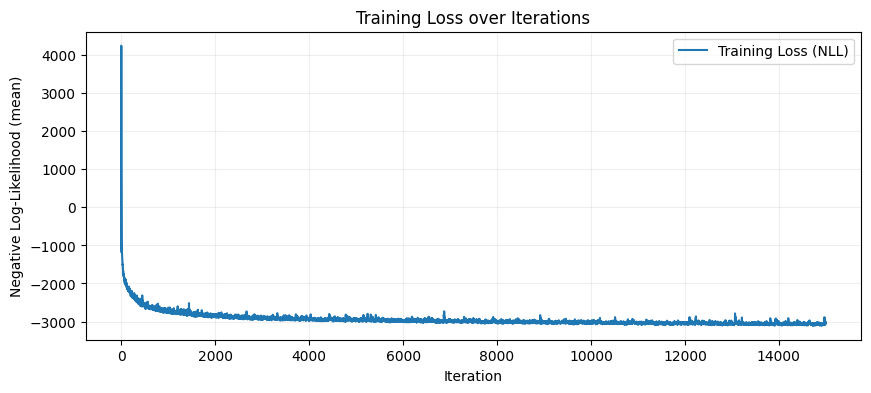

In [20]:
# Plot training loss
plt.figure(figsize=(10, 4))
plt.plot(loss_hist, label='Training Loss (NLL)')
plt.xlabel('Iteration')
plt.ylabel('Negative Log-Likelihood (mean)')
plt.legend()
plt.title('Training Loss over Iterations')
plt.grid(alpha=0.2)
plt.show()

## Evaluation

To evaluate our model, we first draw samples from our model. When sampling, we can specify the classes, so we draw the samples from each class.

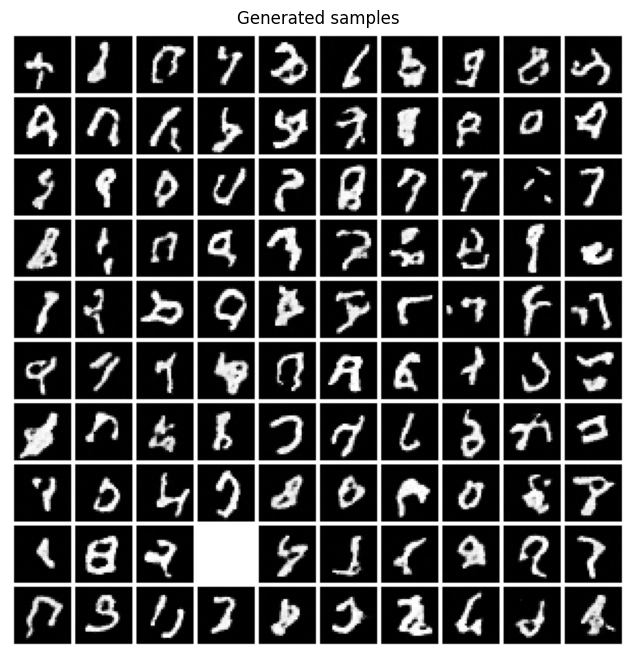

In [21]:
num_samples_per_row = 10
n_samples = num_samples_per_row ** 2

model.eval()
with torch.no_grad():
    x_samples, _ = model.sample(n_samples)  # probably returns tensor in same scale as inputs
    x_clamped = torch.clamp(x_samples, 0.0, 1.0)  # if transform expects [0,1] display
    grid = tv.utils.make_grid(x_clamped.cpu(), nrow=num_samples_per_row, pad_value=1.0)

plt.figure(figsize=(8, 8))
# if single-channel, squeeze channel axis into colormap
if grid.shape[0] == 1:
    plt.imshow(grid.squeeze(0), cmap='gray')
else:
    plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
plt.axis('off')
plt.title('Generated samples')
plt.show()

Note that to get competitive performance, a much larger model then specified in this notebook, which is trained over more iterations, is needed.

## In-Painting

In [22]:
#@title Inpainting utilities

import torchvision.transforms.functional as TF

def apply_random_square_mask(image, mask_size=8):
    C, H, W = image.shape
    assert C == 1 or C == 3

    masked_image = image.clone()
    mask = torch.zeros((H, W), dtype=torch.float32, device=image.device)

    top = np.random.randint(0, H - mask_size + 1)
    left = np.random.randint(0, W - mask_size + 1)

    masked_image[:, top:top + mask_size, left:left + mask_size] = 0.0
    mask[top:top + mask_size, left:left + mask_size] = 1.0

    return masked_image, mask


def apply_random_noise_mask(image, noise_fraction=0.2):
    C, H, W = image.shape

    masked_image = image.clone()
    mask = torch.zeros((H, W), dtype=torch.float32, device=image.device)

    num_noise = int(noise_fraction * H * W)
    num_noise = max(0, min(num_noise, H * W))

    flat_idx = np.random.choice(H * W, size=num_noise, replace=False)
    ys = flat_idx // W
    xs = flat_idx % W

    ys_t = torch.as_tensor(ys, device=image.device, dtype=torch.long)
    xs_t = torch.as_tensor(xs, device=image.device, dtype=torch.long)

    noise = 2.0 * torch.rand((C, num_noise), device=image.device) - 1.0
    masked_image[:, ys_t, xs_t] = noise

    mask[ys_t, xs_t] = 1.0

    return masked_image, mask


def visualize_masking(original_image, masked_image, mask, title="Masking Example"):
    """
    Accepts tensors [C,H,W] (C maybe 1)
    """
    orig = original_image.squeeze().cpu().numpy()
    masked = masked_image.squeeze().cpu().numpy()
    mask_np = mask.cpu().numpy()

    fig, axs = plt.subplots(1, 3, figsize=(10, 4))
    axs[0].imshow(orig, cmap='gray')
    axs[0].set_title("Original")
    axs[0].axis('off')

    axs[1].imshow(masked, cmap='gray')
    axs[1].set_title("Masked")
    axs[1].axis('off')

    axs[2].imshow(mask_np, cmap='gray')
    axs[2].set_title("Mask")
    axs[2].axis('off')

    plt.suptitle(title)
    plt.show()

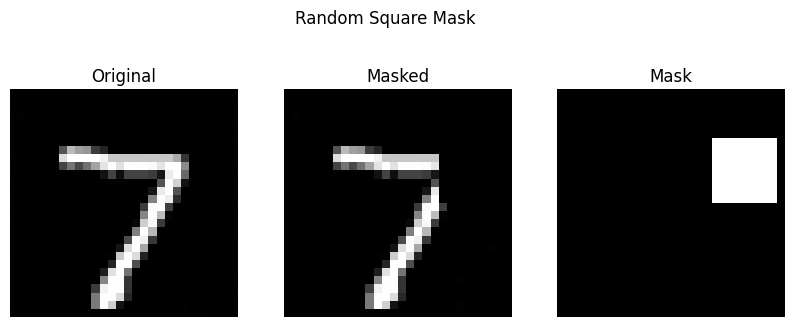

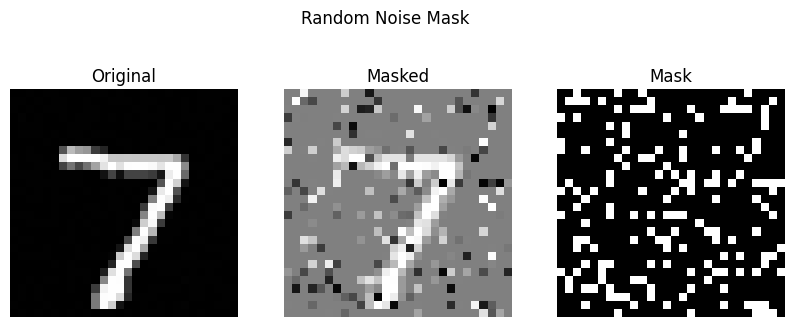

In [23]:
# Example single image from test set
sample_batch = next(iter(test_loader))
sample_image = sample_batch[0][0]  # first sample, shape [C,H,W]

masked_image_sq, mask_sq = apply_random_square_mask(sample_image, mask_size=8)
visualize_masking(sample_image, masked_image_sq, mask_sq, title="Random Square Mask")

masked_image_n, mask_n = apply_random_noise_mask(sample_image, noise_fraction=0.2)
visualize_masking(sample_image, masked_image_n, mask_n, title="Random Noise Mask")

In [24]:
def inpaint_image(model, masked_image, mask, device,
                  num_steps=200, lr=0.01, verbose=True):
    model.eval()

    masked_image = masked_image.to(device)
    mask = mask.to(device)

    C, H, W = masked_image.shape
    mask_ch = mask.unsqueeze(0).expand(C, H, W)

    delta = 0.01 * torch.randn_like(masked_image, device=device, requires_grad=False)
    delta = (delta * mask_ch).detach()
    delta.requires_grad_(True)

    optimizer = torch.optim.Adam([delta], lr=lr)

    pbar = tqdm(range(num_steps), disable=not verbose, desc="Inpainting")
    for _ in pbar:
        optimizer.zero_grad(set_to_none=True)

        x = masked_image + delta * mask_ch

        loss = model.forward_kld(x.unsqueeze(0)).mean()

        if torch.isfinite(loss):
            loss.backward()
            optimizer.step()

        with torch.no_grad():
            x = torch.clamp(x, 0.0, 1.0)
            delta.data = (x - masked_image).mul(mask_ch)

        if verbose:
            pbar.set_postfix({"loss": f"{loss.detach().item():.4f}"})

    with torch.no_grad():
        x_final = torch.clamp(masked_image + delta * mask_ch, 0.0, 1.0)

    return x_final.detach().cpu()


def inpaint_batch(model, masked_images, masks, device, num_steps=200, lr=0.01):
    model.eval()

    results = []
    N = masked_images.size(0)

    for i in range(N):
        recon = inpaint_image(
            model=model,
            masked_image=masked_images[i],
            mask=masks[i],
            device=device,
            num_steps=num_steps,
            lr=lr,
            verbose=False
        )
        results.append(recon)

    return torch.stack(results, dim=0)


In [25]:
model = model.to(device)
model.eval()

# take a small batch
batch_images, _ = next(iter(test_loader))
batch_images = batch_images[:4]  # N=4
masked_imgs = []
masks = []
for img in batch_images:
    mimg, m = apply_random_square_mask(img, mask_size=8)
    masked_imgs.append(mimg)
    masks.append(m)
masked_imgs = torch.stack(masked_imgs)
masks = torch.stack(masks)

# Run inpainting (note: might be slow; lower num_steps to test)
inpainted = inpaint_batch(model, masked_imgs, masks, device, num_steps=200, lr=0.01)

**NOTE**: Actually getting good in-paintings requires a bigger model. So your score will be determined based on your codes logic and and your outputs being without logic/code bugs.

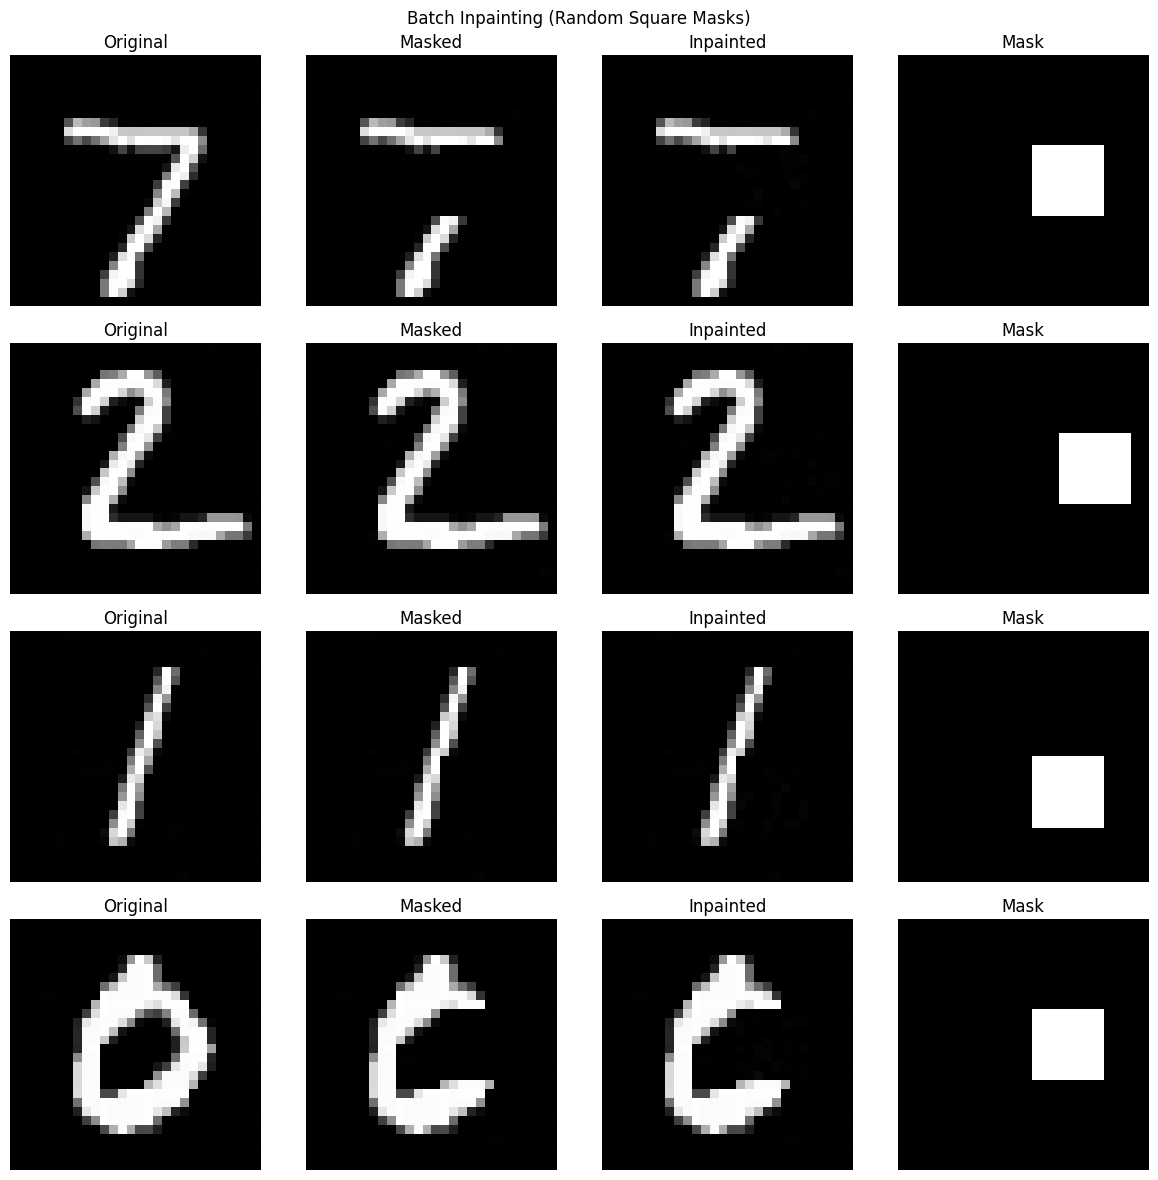

In [26]:
def visualize_batch_inpainting(originals, masked, inpainted, masks, title="Batch Inpainting Results"):
    N = originals.size(0)
    fig, axs = plt.subplots(N, 4, figsize=(12, 3 * N))
    for i in range(N):
        orig = originals[i].squeeze().cpu().numpy()
        maskd = masked[i].squeeze().cpu().numpy()
        inp = inpainted[i].squeeze().cpu().numpy()
        m = masks[i].cpu().numpy()

        axs[i,0].imshow(orig, cmap='gray'); axs[i,0].set_title('Original'); axs[i,0].axis('off')
        axs[i,1].imshow(maskd, cmap='gray'); axs[i,1].set_title('Masked'); axs[i,1].axis('off')
        axs[i,2].imshow(inp, cmap='gray'); axs[i,2].set_title('Inpainted'); axs[i,2].axis('off')
        axs[i,3].imshow(m, cmap='gray'); axs[i,3].set_title('Mask'); axs[i,3].axis('off')

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

visualize_batch_inpainting(batch_images, masked_imgs, inpainted, masks, title="Batch Inpainting (Random Square Masks)")